<a href="https://colab.research.google.com/github/sedillos2/DSCI-Data-Mining-/blob/main/Association_Analysis_Project_Sedillo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Association Analysis Project

I worked through the 6 steps posted in blackboard for this project, and answered the questions found in steps 2, 4, 5, and 6 - throughout this notebook.

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import pandas as pd
import seaborn as sns
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
path = '/content/drive/MyDrive/Groceries_dataset.csv'
Groceries_dataset = pd.read_csv(path, header = None)

In [ ]:
Groceries_dataset.head()

,0,1,2
0,Member_number,Date,itemDescription
1,1808,21-07-2015,tropical fruit
2,2552,05-01-2015,whole milk
3,2300,19-09-2015,pip fruit
4,1187,12-12-2015,other vegetables


In [ ]:
Groceries_dataset.shape

(38766, 3)

In [ ]:
Groceries_dataset.isna().sum().sum()

np.int64(0)

In [ ]:
top_10_items = Groceries_dataset[2].value_counts().head(10)
print(top_10_items)

2
whole milk          2502
other vegetables    1898
rolls/buns          1716
soda                1514
yogurt              1334
root vegetables     1071
tropical fruit      1032
bottled water        933
sausage              924
citrus fruit         812
Name: count, dtype: int64


2) The top 10 most frequently purchased items before grouping Member_number and Date are listed above.

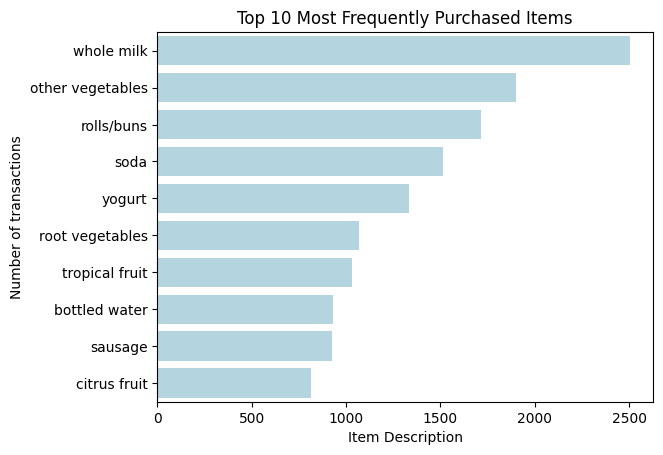

In [ ]:
import matplotlib.pyplot as plt

top_10_items = Groceries_dataset[2].value_counts().head(10)
data = top_10_items.values

sns.barplot(x=top_10_items.values, y=top_10_items.index, color='lightblue')

plt.xlabel('Item Description')
plt.ylabel('Number of transactions')
plt.title('Top 10 Most Frequently Purchased Items')
plt.tight_layout
plt.show()

Below is grouping Member_number and Date

In [ ]:
Transactional_data = Groceries_dataset.groupby([0, 1])[2].apply(list).reset_index()

In [ ]:
print('New Transactional Data')
display(Transactional_data.head())

New Transactional Data


,0,1,2
0,1000,15-03-2015,"[sausage, whole milk, semi-finished bread, yog..."
1,1000,24-06-2014,"[whole milk, pastry, salty snack]"
2,1000,24-07-2015,"[canned beer, misc. beverages]"
3,1000,25-11-2015,"[sausage, hygiene articles]"
4,1000,27-05-2015,"[soda, pickled vegetables]"


Of the new transactional data, below are the top 10 most frequently purchased items

In [ ]:
top_10_items = Transactional_data[2].value_counts().head(10)
print(top_10_items)

2
[other vegetables, whole milk]        48
[whole milk, whole milk]              40
[whole milk, rolls/buns]              38
[sausage, whole milk]                 37
[whole milk, other vegetables]        37
[citrus fruit, whole milk]            32
[other vegetables, rolls/buns]        30
[tropical fruit, other vegetables]    30
[frankfurter, whole milk]             27
[whole milk, soda]                    26
Name: count, dtype: int64


In [ ]:
Transactional_data.shape

(14964, 3)

In [ ]:
unique_items_set = set()

for transactions_list in Transactional_data[2]:
    for item in transactions_list:
        unique_items_set.add(item)

unique_items = list(unique_items_set)

unique_items = [x for x in unique_items if str(x) != 'nan']

In [ ]:
# one hot encoding for supplying data in the apriori algorithm
encoded_vals = []

for i, rows in Transactional_data.iterrows():
  labels={}
  uncommons=list( set(unique_items)-set(rows[2]))
  commons=list( set(unique_items).intersection(set(rows[2])))
  for un in uncommons:
    labels[un] = 0
  for com in commons:
    labels[com] = 1
  encoded_vals.append(labels)
# create a dtaframe for enocoded data
encoded_data = pd.DataFrame(encoded_vals)
#print("\nOne hot encoded data:\n", encoded_data.head(10),"\n")

In [ ]:
encoded_data.head()

,spices,cocoa drinks,cat food,waffles,margarine,salad dressing,flour,salt,white wine,specialty bar,...,bottled beer,canned fish,pastry,potato products,liver loaf,curd,sausage,semi-finished bread,yogurt,whole milk
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,1,1
1,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
frequent_items = apriori(encoded_data, min_support=0.006, use_colnames=True, verbose=1)

Processing 138 combinations | Sampling itemset size 3


In [ ]:
print("Top 15 frequent items:\n",frequent_items.head(15),"\n")

Top 15 frequent items:
      support                     itemsets
0   0.011828                   (cat food)
1   0.018511                    (waffles)
2   0.032211                  (margarine)
3   0.009757                      (flour)
4   0.011695                 (white wine)
5   0.013967              (specialty bar)
6   0.046913                (canned beer)
7   0.027867                    (chicken)
8   0.016840                       (meat)
9   0.008086              (baking powder)
10  0.006683              (spread cheese)
11  0.014368                      (candy)
12  0.007084          (seasonal products)
13  0.008487  (packaged fruit/vegetables)
14  0.010492             (red/blush wine) 



4) With a minimum support = .006, the minimum support count of an itemset in order for the itemset to be considered frequent is 90 transactions. I found the number of transactions N by looking at the number of rows in the Transactions_data (dataset that grouped Member_number and Date) which was 14964 rows of transactions, and multiplying by .006.

In [ ]:
association_rule_generated_confidence= association_rules(frequent_items, metric="confidence", min_threshold=0.005)

In [ ]:
association_rule_generated_confidence.sort_values('confidence', ascending=False, inplace=True)
association_rule_generated_confidence[['antecedents', 'consequents', 'support', 'confidence']].head(15)

,antecedents,consequents,support,confidence
36,(bottled beer),(whole milk),0.007150,0.157817
40,(sausage),(whole milk),0.008955,0.148394
10,(pip fruit),(whole milk),0.006616,0.134877
32,(citrus fruit),(whole milk),0.007150,0.134591
34,(shopping bags),(whole milk),0.006349,0.133427
42,(yogurt),(whole milk),0.011160,0.129961
0,(canned beer),(whole milk),0.006014,0.128205
18,(rolls/buns),(whole milk),0.013967,0.126974
38,(pastry),(whole milk),0.006482,0.125323
26,(other vegetables),(whole milk),0.014836,0.121511


5) Majority (14 out of the 15) consequents are whole milk even though all fifteen antecedents vary. I think when you look back at the top 10 most frequently purchased items, whole milk is the highest by a decent margin, making it very common to buy. So common, it doesnt have a strong association to other items bought.

In [ ]:
frequent_items = apriori(encoded_data, min_support=0.008, use_colnames=True, verbose=1)

Processing 42 combinations | Sampling itemset size 3


In [ ]:
association_rule_generated_confidence= association_rules(frequent_items, metric="confidence", min_threshold=0.05)

In [ ]:
association_rule_generated_confidence.sort_values('confidence', ascending=False, inplace=True)
association_rule_generated_confidence[['antecedents', 'consequents', 'support', 'confidence']].head(15)

,antecedents,consequents,support,confidence
16,(sausage),(whole milk),0.008955,0.148394
18,(yogurt),(whole milk),0.011160,0.129961
8,(rolls/buns),(whole milk),0.013967,0.126974
12,(other vegetables),(whole milk),0.014836,0.121511
14,(tropical fruit),(whole milk),0.008220,0.121302
4,(soda),(whole milk),0.011628,0.119752
2,(soda),(other vegetables),0.009690,0.099794
6,(rolls/buns),(other vegetables),0.010559,0.095990
10,(yogurt),(other vegetables),0.008086,0.094163
13,(whole milk),(other vegetables),0.014836,0.093948


6) I decided to raise the min support from .006 to .008 and really change the confidence from .005 to .05 (5% confidence) which filtered out weak rules, showing other consequents besides whole milk. One piece of information I would share with my stakeholders is to not expend energy analyzing an antecedent consequent relationship where the consequent is whole milk. Customers are buying it regardless of other grocery items, so focus on other predictive relationships, like researching the relationship between (rolls/buns) and (other vegetables).